In [1]:
!pip install -q timm torchmetrics thop grad-cam kaggle torchinfo

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Imports and reproducibility

In [2]:
import os
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix,
    classification_report
)
from thop import profile
from torchinfo import summary

sns.set_style("darkgrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device)
print("Mixed precision:", USE_AMP)
print("timm version:", timm.__version__)
from timm.models.vision_transformer import VisionTransformer


Device: cuda
Mixed precision: True
timm version: 1.0.30


## 3. Kaggle authentication

For safety, this notebook does **not** contain the Kaggle API key from the source notebook. Upload your own `kaggle.json` downloaded from your Kaggle account (**Kaggle → Settings → API → Create New Token**). If running outside Colab, place the file at `~/.kaggle/kaggle.json` yourself.

In [3]:
# Google Colab: upload kaggle.json when prompted.
try:
    from google.colab import files
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("Please upload a file named kaggle.json")
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    with open(kaggle_dir / "kaggle.json", "wb") as f:
        f.write(uploaded["kaggle.json"])
    os.chmod(kaggle_dir / "kaggle.json", 0o600)
    print("Kaggle credentials configured.")
except ImportError:
    kaggle_path = Path.home() / ".kaggle" / "kaggle.json"
    if not kaggle_path.exists():
        raise FileNotFoundError(
            f"Place your Kaggle API token at {kaggle_path} before continuing."
        )
    os.chmod(kaggle_path, 0o600)
    print("Using existing Kaggle credentials:", kaggle_path)

Saving kaggle.json to kaggle.json
Kaggle credentials configured.


## 4. Download the same dataset

In [4]:
from kaggle.api.kaggle_api_extended import KaggleApi

DATA_DIR = Path("brain_tumor_mri_data")
DATASET = "sartajbhuvaji/brain-tumor-classification-mri"

if not DATA_DIR.exists() or not any(DATA_DIR.iterdir()):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files(DATASET, path=str(DATA_DIR), unzip=True)

print("Dataset directory:", DATA_DIR.resolve())
print("Top-level entries:", [p.name for p in DATA_DIR.iterdir()][:20])

Dataset URL: https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri
Dataset directory: /content/brain_tumor_mri_data
Top-level entries: ['Training', 'Testing']


## 5. Build the image dataframe

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

# Locate the directory whose immediate subfolders are the image classes.
class_root_candidates = []
for root, dirs, files in os.walk(DATA_DIR):
    root_path = Path(root)
    valid_class_dirs = []
    for dirname in dirs:
        child = root_path / dirname
        image_count = sum(1 for p in child.iterdir()
                          if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        if image_count > 0:
            valid_class_dirs.append((child, image_count))
    if len(valid_class_dirs) >= 2:
        class_root_candidates.append((root_path, sum(n for _, n in valid_class_dirs), valid_class_dirs))

if not class_root_candidates:
    raise RuntimeError(
        "Could not identify class folders. Inspect the extracted dataset structure and set DATA_ROOT manually."
    )

# Prefer the candidate with the largest number of images in its immediate class folders.
DATA_ROOT, _, class_dirs_info = max(class_root_candidates, key=lambda x: x[1])
class_names = sorted([p.name for p, _ in class_dirs_info])
label_map = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in label_map.items()}

records = []
for class_name in class_names:
    class_dir = DATA_ROOT / class_name
    for image_path in sorted(class_dir.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            records.append({
                "image_path": str(image_path),
                "label": label_map[class_name],
                "class_name": class_name
            })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError(f"No images found under {DATA_ROOT}")

num_classes = len(class_names)
print("Selected data root:", DATA_ROOT)
print("Classes:", label_map)
print("Total images:", len(df))
print("Class distribution:\n", df["class_name"].value_counts())
display(df.head())

Selected data root: brain_tumor_mri_data/Training
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
Total images: 2870
Class distribution:
 class_name
pituitary_tumor     827
glioma_tumor        826
meningioma_tumor    822
no_tumor            395
Name: count, dtype: int64


,image_path,label,class_name
0,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
1,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
2,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
3,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
4,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor


## 6. Train / validation / test split

In [6]:
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED
)
train_df, val_df = train_test_split(
    train_df, test_size=0.20, stratify=train_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

Train: 1836 | Validation: 460 | Test: 574


## 7. Dataset, transforms, and dataloaders

In [7]:
class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(int(row["label"]), dtype=torch.long)

train_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 8  # Memory-conscious for ConvNeXt + CBAM + ViT
NUM_WORKERS = 2
pin_memory = device.type == "cuda"

train_loader = DataLoader(BrainTumorDataset(train_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(BrainTumorDataset(val_df, val_test_transform),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(BrainTumorDataset(test_df, val_test_transform),
                         batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 918 230 287


In [8]:

# ============================================================
# CONVNEXT + ONE SNN BLOCK + VISION TRANSFORMER
# COMPLETE ARCHITECTURE
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from timm.models.vision_transformer import VisionTransformer


# ============================================================
# 1. SURROGATE SPIKE FUNCTION
# ============================================================

class SurrogateSpike(torch.autograd.Function):

    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return (x > 0).float()

    @staticmethod
    def backward(ctx, grad_output):

        (x,) = ctx.saved_tensors

        slope = 5.0

        grad = 1.0 / (
            1.0 + slope * torch.abs(x)
        ) ** 2

        return grad_output * grad


# ============================================================
# 2. LIF SPIKING NEURON
# ============================================================

class LIFNeuron(nn.Module):

    def __init__(
        self,
        threshold=1.0,
        decay=0.5,
        num_steps=4
    ):
        super().__init__()

        self.threshold = threshold
        self.decay = decay
        self.num_steps = num_steps

    def forward(self, current):

        membrane = torch.zeros_like(current)

        spike_sequence = []

        for t in range(self.num_steps):

            # Membrane potential integration
            membrane = (
                self.decay * membrane + current
            )

            # Spike generation
            spike = SurrogateSpike.apply(
                membrane - self.threshold
            )

            # Soft reset
            membrane = (
                membrane -
                spike.detach() * self.threshold
            )

            spike_sequence.append(spike)

        # Temporal firing-rate aggregation
        output = torch.stack(
            spike_sequence, dim=0
        ).mean(dim=0)

        return output


# ============================================================
# 3. ONE SNN BLOCK
# ============================================================

class SNNBlock(nn.Module):

    def __init__(
        self,
        channels=192,
        kernel_size=3,
        num_steps=4,
        threshold=1.0,
        decay=0.5
    ):
        super().__init__()

        self.num_steps = num_steps

        # Spatial feature transformation
        self.conv = nn.Conv2d(
            in_channels=channels,
            out_channels=channels,
            kernel_size=kernel_size,
            stride=1,
            padding=kernel_size // 2,
            bias=False
        )

        self.bn = nn.BatchNorm2d(channels)

        # LIF neuron
        self.lif = LIFNeuron(
            threshold=threshold,
            decay=decay,
            num_steps=num_steps
        )

    def forward(self, x):

        identity = x

        current = self.conv(x)
        current = self.bn(current)

        spike_output = self.lif(current)

        # Residual connection
        output = identity + spike_output

        return output


# ============================================================
# 4. CONVNEXT + SNN + VIT
# ============================================================

class ConvNeXtSNNViT(nn.Module):

    def __init__(
        self,
        num_classes,
        pretrained=True
    ):
        super().__init__()

        # ----------------------------------------------------
        # CONVNEXT-TINY BACKBONE
        # ----------------------------------------------------

        base = timm.create_model(
            "convnext_tiny",
            pretrained=pretrained,
            num_classes=0
        )

        self.stem = base.stem

        stage1 = base.stages[0]
        stage2 = base.stages[1]

        # Retain 3 blocks from stage 1
        # Retain 1 block from stage 2

        stage2.blocks = nn.Sequential(
            *list(stage2.blocks.children())[:1]
        )

        self.stages = nn.Sequential(
            stage1,
            stage2
        )

        del base

        self.feature_channels = 192

        # ----------------------------------------------------
        # ONE SNN BLOCK
        # ----------------------------------------------------

        self.snn_block = SNNBlock(
            channels=192,
            kernel_size=3,
            num_steps=4,
            threshold=1.0,
            decay=0.5
        )

        # ----------------------------------------------------
        # MAX POOLING
        # ----------------------------------------------------

        self.max_pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # ----------------------------------------------------
        # 1x1 CONVOLUTION: 192 -> 96
        # ----------------------------------------------------

        self.conv1x1 = nn.Conv2d(
            in_channels=192,
            out_channels=96,
            kernel_size=1,
            stride=1,
            padding=0
        )

        # ----------------------------------------------------
        # 3x3 CONVOLUTION: 96 -> 64
        # ----------------------------------------------------

        self.conv3x3 = nn.Conv2d(
            in_channels=96,
            out_channels=64,
            kernel_size=3,
            stride=1,
            padding=1
        )

        # ----------------------------------------------------
        # VISION TRANSFORMER
        # ----------------------------------------------------

        self.vit_encoder = VisionTransformer(

            img_size=28,
            patch_size=7,
            in_chans=64,

            num_classes=0,
            global_pool="avg",

            embed_dim=64,
            depth=2,
            num_heads=4,

            mlp_ratio=1,
            qkv_bias=True,

            norm_layer=nn.LayerNorm,
            act_layer=nn.ReLU
        )

        self.vit_encoder.head = nn.Identity()

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            64,
            num_classes
        )

    # ========================================================
    # CONVNEXT FEATURE EXTRACTION
    # ========================================================

    def forward_features(self, x):

        x = self.stem(x)

        x = self.stages(x)

        return x

    # ========================================================
    # SNN + CONVOLUTION + VIT FEATURE EXTRACTION
    # ========================================================

    def forward_head_features(self, x):

        # ConvNeXt backbone
        x = self.forward_features(x)
        # B, 192, 56, 56

        # One SNN block
        x = self.snn_block(x)
        # B, 192, 56, 56

        # Max pooling
        x = self.max_pool(x)
        # B, 192, 28, 28

        # 1x1 convolution
        x = self.conv1x1(x)
        # B, 96, 28, 28

        # 3x3 convolution
        x = self.conv3x3(x)
        # B, 64, 28, 28

        # Direct 4D feature-map input to ViT
        # No manual flattening before ViT
        x = self.vit_encoder(x)
        # B, 64

        return x

    # ========================================================
    # FINAL CLASSIFICATION
    # ========================================================

    def forward(self, x):

        features = self.forward_head_features(x)

        logits = self.classifier(features)

        return logits


# ============================================================
# 5. MODEL INITIALIZATION
# ============================================================

model = ConvNeXtSNNViT(
    num_classes=num_classes,
    pretrained=True
).to(device)


# ============================================================
# 6. VERIFY CONVNEXT BLOCKS
# ============================================================

retained_block_counts = [
    len(stage.blocks)
    for stage in model.stages
]

assert retained_block_counts == [3, 1]

assert sum(retained_block_counts) == 4


# ============================================================
# 7. ARCHITECTURE DIMENSION VERIFICATION
# ============================================================

model.eval()

with torch.no_grad():

    dummy = torch.randn(
        1, 3, 448, 448,
        device=device
    )

    backbone_map = model.forward_features(dummy)

    snn_map = model.snn_block(backbone_map)

    pooled_map = model.max_pool(snn_map)

    map_96 = model.conv1x1(pooled_map)

    map_64 = model.conv3x3(map_96)

    vit_features = model.vit_encoder(map_64)

    logits = model(dummy)


# ============================================================
# 8. PRINT ARCHITECTURE OUTPUTS
# ============================================================

print("\n========================================")
print("     CONVNEXT + SNN + VIT ARCHITECTURE")
print("========================================")

print(
    "Retained ConvNeXt blocks:",
    retained_block_counts
)

print(
    "ConvNeXt output:",
    tuple(backbone_map.shape)
)

print(
    "After SNN:",
    tuple(snn_map.shape)
)

print(
    "After MaxPool:",
    tuple(pooled_map.shape)
)

print(
    "After 1x1 Conv:",
    tuple(map_96.shape)
)

print(
    "After 3x3 Conv:",
    tuple(map_64.shape)
)

print(
    "ViT input:",
    tuple(map_64.shape)
)

print(
    "ViT output:",
    tuple(vit_features.shape)
)

print(
    "Classifier output:",
    tuple(logits.shape)
)


# ============================================================
# 9. SHAPE ASSERTIONS
# ============================================================

assert tuple(backbone_map.shape[1:]) == (
    192, 56, 56
)

assert tuple(snn_map.shape[1:]) == (
    192, 56, 56
)

assert tuple(pooled_map.shape[1:]) == (
    192, 28, 28
)

assert tuple(map_96.shape[1:]) == (
    96, 28, 28
)

assert tuple(map_64.shape[1:]) == (
    64, 28, 28
)

assert tuple(vit_features.shape) == (
    1, 64
)

assert tuple(logits.shape) == (
    1, num_classes
)

print("\nAll architecture dimensions verified!")

model.train()


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


     CONVNEXT + SNN + VIT ARCHITECTURE
Retained ConvNeXt blocks: [3, 1]
ConvNeXt output: (1, 192, 56, 56)
After SNN: (1, 192, 56, 56)
After MaxPool: (1, 192, 28, 28)
After 1x1 Conv: (1, 96, 28, 28)
After 3x3 Conv: (1, 64, 28, 28)
ViT input: (1, 64, 28, 28)
ViT output: (1, 64)
Classifier output: (1, 4)

All architecture dimensions verified!


ConvNeXtSNNViT(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), group

## 9. Model summary and complexity

The model summary includes the four retained ConvNeXt blocks, CBAM, and classification head.

In [9]:
summary(
    model,
    input_size=(1, 3, 448, 448),
    col_names=["input_size", "output_size", "num_params", "kernel_size"],
    depth=4
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

model.eval()
dummy_input = torch.randn(1, 3, 448, 448, device=device)
flops, thop_params = profile(model, inputs=(dummy_input,), verbose=False)
print(f"THOP FLOPs: {flops:,.0f} ({flops / 1e9:.4f} GFLOPs)")
print(f"THOP parameters: {thop_params:,.0f} ({thop_params / 1e6:.4f} M)")
model.train()

Trainable parameters: 1,281,732
Total parameters: 1,281,732
THOP FLOPs: 5,299,639,808 (5.2996 GFLOPs)
THOP parameters: 1,278,756 (1.2788 M)


ConvNeXtSNNViT(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), group

## 10. Loss, optimizer, and learning-rate schedule

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4, betas=(0.9, 0.999)
)

TOTAL_EPOCHS = 35
WARMUP_EPOCHS = 5
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=TOTAL_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
BEST_MODEL_PATH = "best_convnext_cbam_vit.pth"
print("Checkpoint:", BEST_MODEL_PATH)

Checkpoint: best_convnext_cbam_vit.pth


## 11. Metric helpers

In [11]:
def specificity_sensitivity(y_true, y_pred, n_classes):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    specificity, sensitivity = [], []
    for i in range(n_classes):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specificity.append(tn / (tn + fp + 1e-8))
        sensitivity.append(tp / (tp + fn + 1e-8))
    return float(np.mean(specificity)), float(np.mean(sensitivity))


def calculate_metrics(y_true, y_pred, y_prob, n_classes):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    try:
        if n_classes == 2:
            metrics["auc"] = roc_auc_score(y_true, y_prob[:, 1])
        else:
            metrics["auc"] = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    except ValueError:
        metrics["auc"] = float("nan")
    metrics["specificity"], metrics["sensitivity"] = specificity_sensitivity(
        y_true, y_pred, n_classes
    )
    return metrics

In [12]:
!pip install torchinfo thop torchview graphviz -q

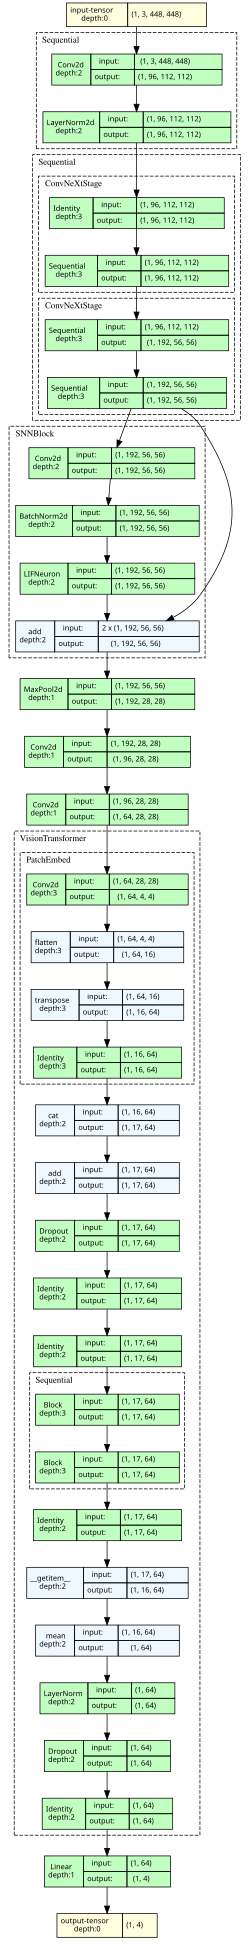

In [13]:
from torchview import draw_graph
from IPython.display import SVG, display

dummy_input = torch.randn(1, 3, 448, 448).to(device)

graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="ConvNeXtCBAMViT",
    save_graph=True,              # IMPORTANT
    filename="ConvNeXtCBAMViT_BlockDiagram",
    directory="."
)

# Display inline
svg = graph.visual_graph.pipe(format="svg")
display(SVG(svg))


## 12. Training and validation

In [14]:
history = {
    "loss": [], "val_loss": [],
    "accuracy": [], "val_accuracy": [],
    "precision": [], "val_precision": [],
    "recall": [], "val_recall": [],
    "f1": [], "val_f1": [],
    "auc": [], "val_auc": [],
    "mcc": [], "val_mcc": [],
    "specificity": [], "val_specificity": [],
    "sensitivity": [], "val_sensitivity": []
}

best_val_acc = -1.0
patience = 7
patience_counter = 0

for epoch in range(TOTAL_EPOCHS):
    # -------------------- TRAIN --------------------
    model.train()
    running_loss = 0.0
    train_true, train_pred, train_prob = [], [], []

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Train")
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        probs = torch.softmax(outputs.detach(), dim=1)
        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(outputs.detach().argmax(1).cpu().numpy())
        train_prob.extend(probs.cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}", lr=f"{optimizer.param_groups[0]['lr']:.2e}")

    train_loss = running_loss / max(1, len(train_loader))
    train_metrics = calculate_metrics(
        np.asarray(train_true), np.asarray(train_pred), np.asarray(train_prob), num_classes
    )

    # -------------------- VALIDATION --------------------
    model.eval()
    val_running_loss = 0.0
    val_true, val_pred, val_prob = [], [], []
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Val"):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(outputs.argmax(1).cpu().numpy())
            val_prob.extend(probs.cpu().numpy())

    val_loss = val_running_loss / max(1, len(val_loader))
    val_metrics = calculate_metrics(
        np.asarray(val_true), np.asarray(val_pred), np.asarray(val_prob), num_classes
    )

    # Step scheduler after the epoch.
    if epoch < WARMUP_EPOCHS:
        warmup_scheduler.step()
    else:
        cosine_scheduler.step()

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    for key in train_metrics:
        history[key].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])

    print(
        f"\nEpoch {epoch+1}: "
        f"train loss={train_loss:.4f}, acc={train_metrics['accuracy']:.4f}, "
        f"F1={train_metrics['f1']:.4f}, AUC={train_metrics['auc']:.4f} | "
        f"val loss={val_loss:.4f}, acc={val_metrics['accuracy']:.4f}, "
        f"F1={val_metrics['f1']:.4f}, AUC={val_metrics['auc']:.4f}"
    )
    print(
        f"Val precision={val_metrics['precision']:.4f}, recall={val_metrics['recall']:.4f}, "
        f"specificity={val_metrics['specificity']:.4f}, "
        f"sensitivity={val_metrics['sensitivity']:.4f}, MCC={val_metrics['mcc']:.4f}"
    )
    print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6e}")

    if val_metrics["accuracy"] > best_val_acc:
        best_val_acc = val_metrics["accuracy"]
        patience_counter = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "num_classes": num_classes,
            "class_to_idx": label_map,
            "best_val_accuracy": best_val_acc,
            "epoch": epoch + 1,
            "architecture": "Four-block ConvNeXt-Tiny + CBAM + MaxPool + 1x1 Conv(192->96) + 3x3 Conv(96->64) + timm VisionTransformer(img_size=28, patch_size=7, in_chans=64, embed_dim=64, depth=2, num_heads=4, mlp_ratio=1, ReLU) + Linear classifier"
        }, BEST_MODEL_PATH)
        print(f"Saved best checkpoint (val accuracy={best_val_acc:.4f})")
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

print(f"\nBest validation accuracy: {best_val_acc:.4f}")

Epoch 1/35 - Train:   0%|          | 0/918 [00:00<?, ?it/s]

Epoch 1/35 - Val:   0%|          | 0/230 [00:00<?, ?it/s]


Epoch 1: train loss=1.2089, acc=0.4777, F1=0.4494, AUC=nan | val loss=0.9795, acc=0.6609, F1=0.5478, AUC=nan
Val precision=0.6769, recall=0.5783, specificity=0.8812, sensitivity=0.5783, MCC=0.5402
Learning rate: 8.400000e-05
Saved best checkpoint (val accuracy=0.6609)


Epoch 2/35 - Train:   0%|          | 0/918 [00:00<?, ?it/s]

Epoch 2/35 - Val:   0%|          | 0/230 [00:00<?, ?it/s]


Epoch 2: train loss=1.1548, acc=0.5599, F1=0.5375, AUC=nan | val loss=1.1053, acc=0.5543, F1=0.5421, AUC=nan
Val precision=0.6783, recall=0.5488, specificity=0.8457, sensitivity=0.5488, MCC=0.4289
Learning rate: 1.380000e-04


... (109 outputs left out)

Epoch 35/35 - Train:   0%|          | 0/918 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa83ce1af20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa83ce1af20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 35/35 - Val:   0%|          | 0/230 [00:00<?, ?it/s]


Epoch 35: train loss=0.3656, acc=0.9929, F1=0.9933, AUC=nan | val loss=0.4761, acc=0.9543, F1=0.9571, AUC=0.9854
Val precision=0.9582, recall=0.9561, specificity=0.9841, sensitivity=0.9561, MCC=0.9377
Learning rate: 1.000000e-06

Best validation accuracy: 0.9587


## 13. Plot training curves

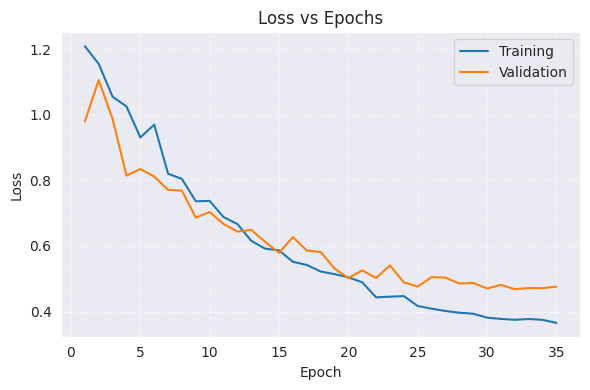

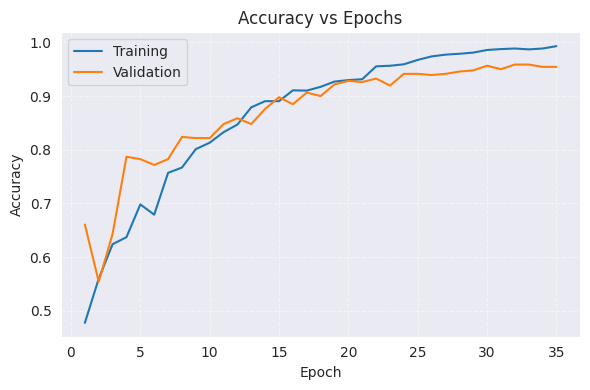

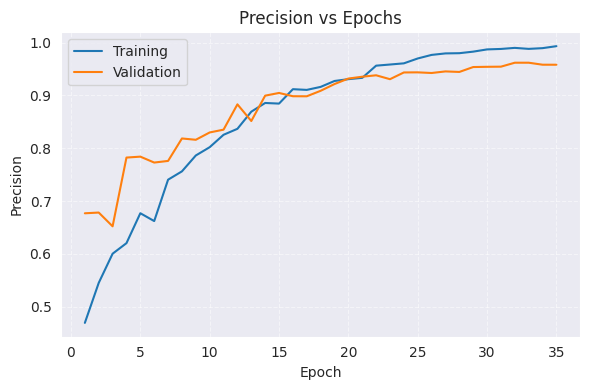

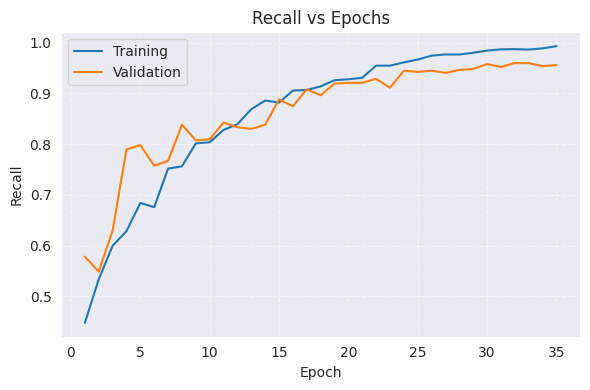

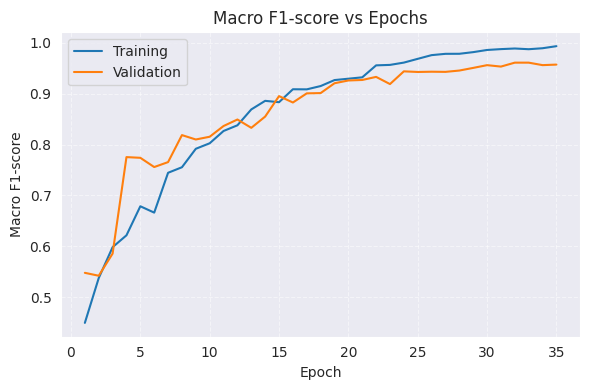

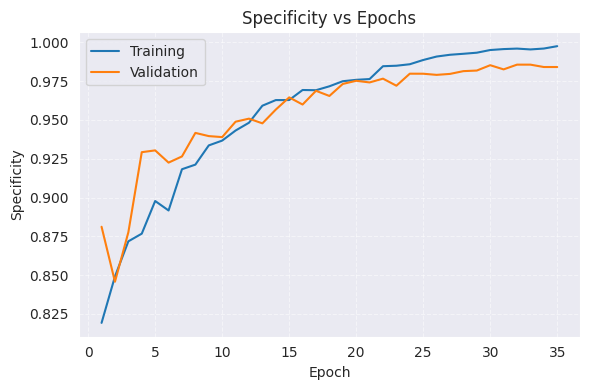

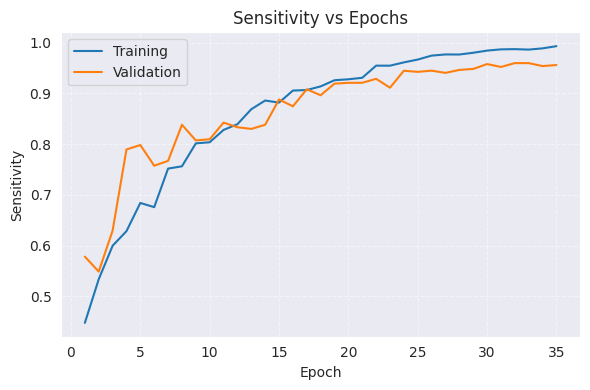

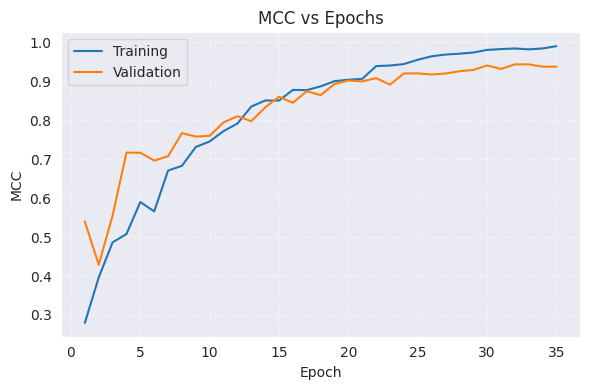

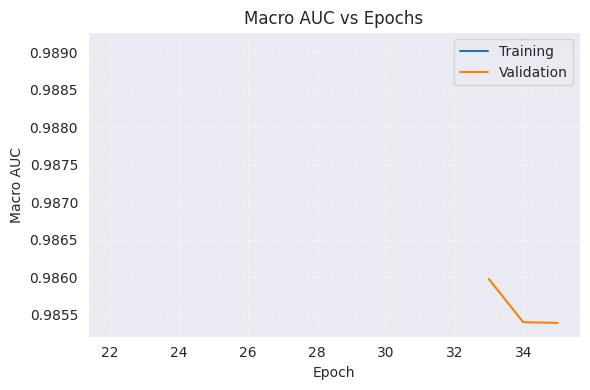

In [15]:
def plot_metric(train_values, val_values, title, ylabel):
    epochs = range(1, len(train_values) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, train_values, label="Training")
    plt.plot(epochs, val_values, label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_metric(history["loss"], history["val_loss"], "Loss vs Epochs", "Loss")
for metric, title in [
    ("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"),
    ("f1", "Macro F1-score"), ("specificity", "Specificity"),
    ("sensitivity", "Sensitivity"), ("mcc", "MCC"), ("auc", "Macro AUC")
]:
    plot_metric(history[metric], history[f"val_{metric}"], f"{title} vs Epochs", title)

## 14. Load best checkpoint and evaluate on the test set

In [16]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_targets, all_preds, all_probs = [], [], []
test_loss = 0.0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        test_loss += loss.item()
        all_targets.extend(labels.cpu().numpy())
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())

all_targets = np.asarray(all_targets)
all_preds = np.asarray(all_preds)
all_probs = np.asarray(all_probs)
test_metrics = calculate_metrics(all_targets, all_preds, all_probs, num_classes)

print(f"Test loss: {test_loss / max(1, len(test_loader)):.4f}")
for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

Testing:   0%|          | 0/287 [00:00<?, ?it/s]

Test loss: 0.4925
accuracy: 0.9443
precision: 0.9454
recall: 0.9367
f1: 0.9400
mcc: 0.9245
auc: nan
specificity: 0.9809
sensitivity: 0.9367


## 15. Classification report and confusion matrix

                  precision    recall  f1-score   support

    glioma_tumor     0.9096    0.9758    0.9415       165
meningioma_tumor     0.9671    0.8909    0.9274       165
        no_tumor     0.9459    0.8861    0.9150        79
 pituitary_tumor     0.9591    0.9939    0.9762       165

        accuracy                         0.9443       574
       macro avg     0.9454    0.9367    0.9400       574
    weighted avg     0.9454    0.9443    0.9438       574



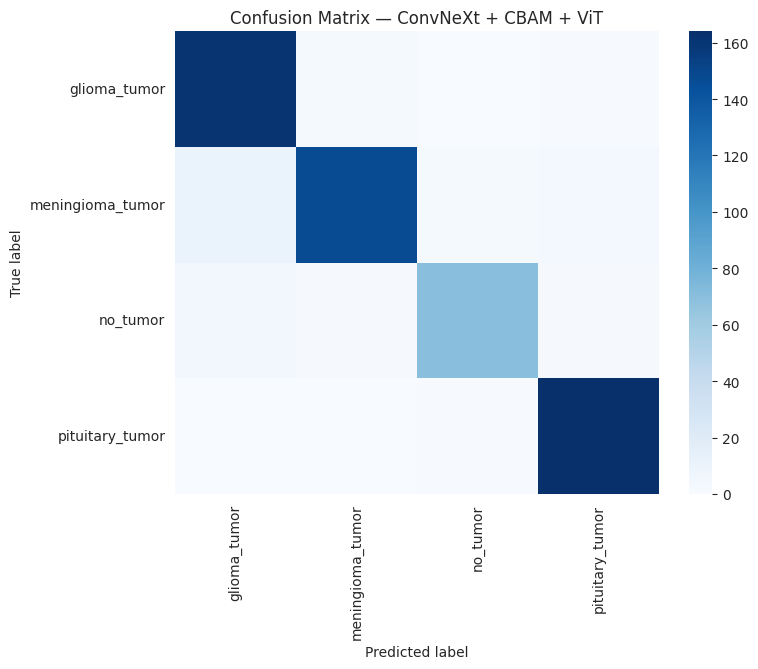

In [17]:
class_names = [idx_to_class[i] for i in range(num_classes)]
print(classification_report(
    all_targets, all_preds, labels=list(range(num_classes)),
    target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_classes)))
fig_size = max(8, min(18, 0.45 * num_classes + 5))
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — ConvNeXt + CBAM + ViT")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Grad-CAM visualizations

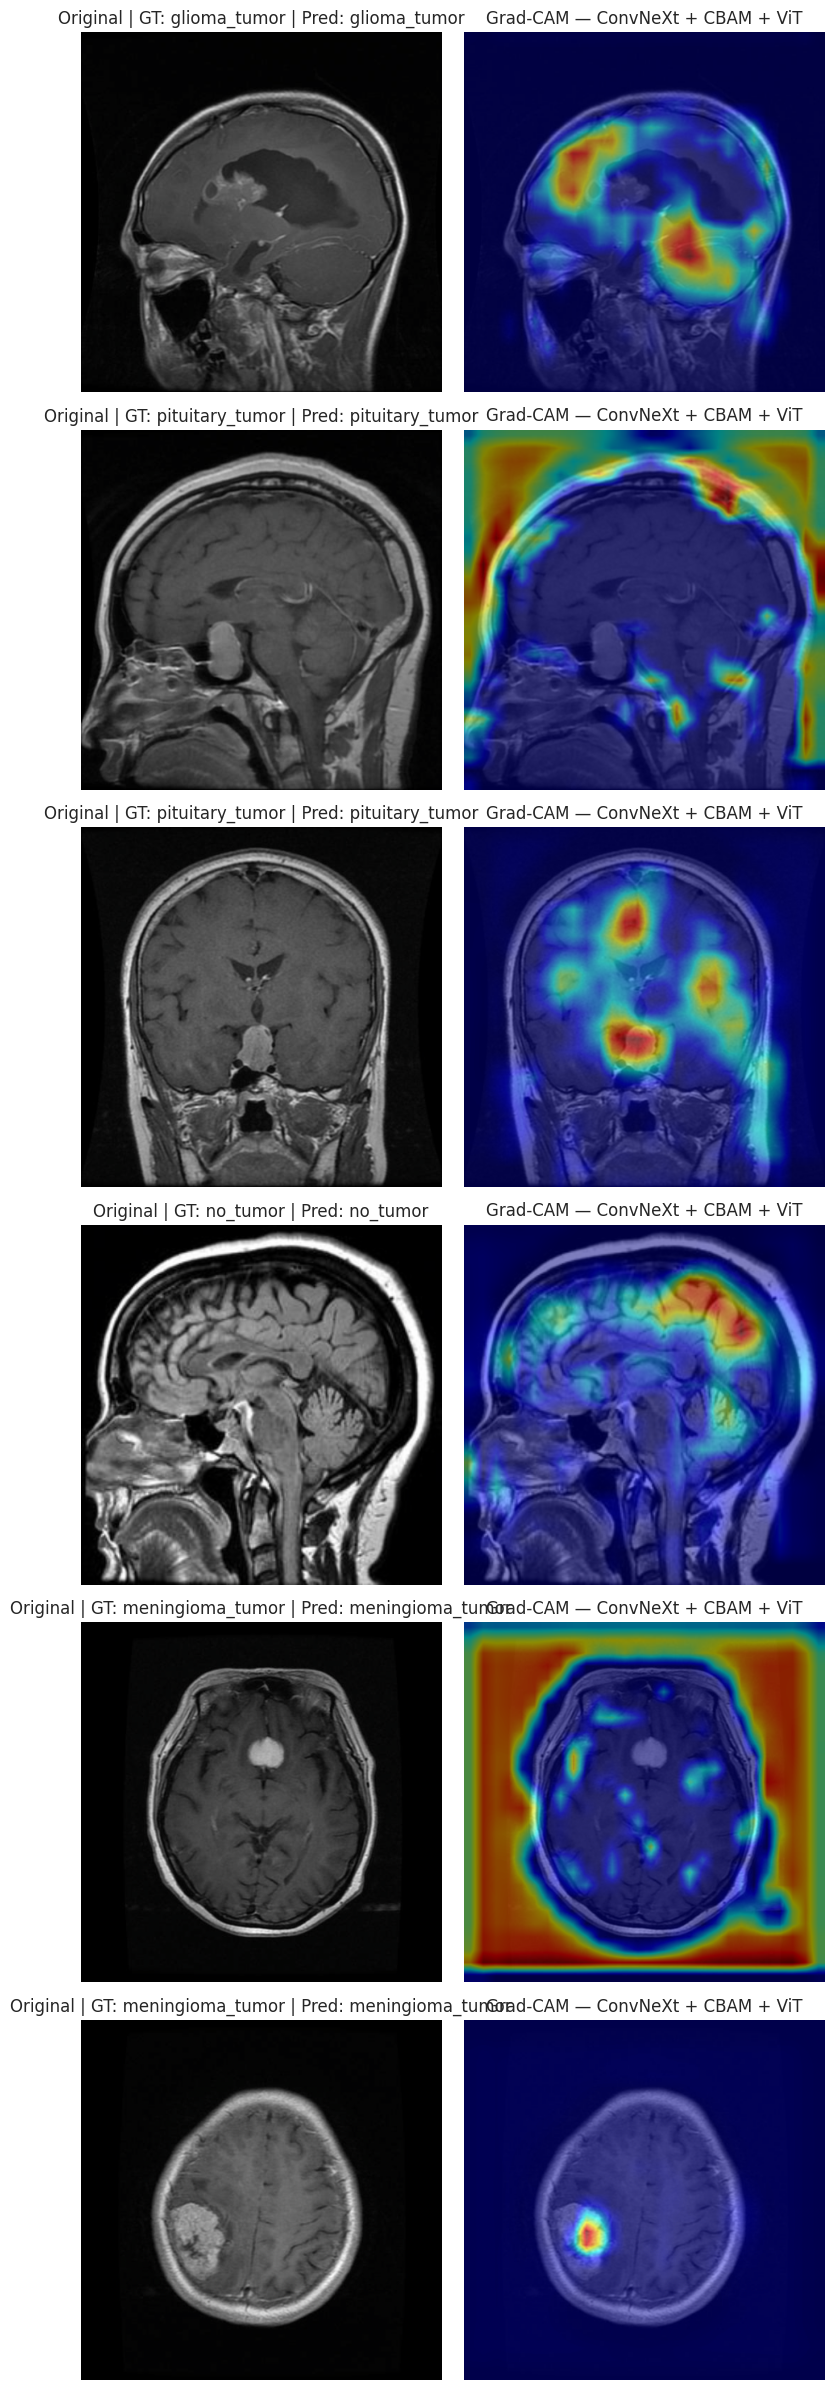

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Grad-CAM target: the 3x3 convolution immediately before ViT patch embedding.
target_layers = [model.conv3x3]
cam = GradCAM(model=model, target_layers=target_layers)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
num_images = min(6, len(test_loader.dataset))
indices = np.random.choice(len(test_loader.dataset), num_images, replace=False)

fig, axes = plt.subplots(num_images, 2, figsize=(8, 4 * num_images))
if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

model.eval()
for i, idx in enumerate(indices):
    img, label = test_loader.dataset[idx]
    input_tensor = img.unsqueeze(0).to(device)

    with torch.no_grad():
        pred_class = model(input_tensor).argmax(dim=1).item()

    rgb = img.permute(1, 2, 0).cpu().numpy()
    rgb = np.clip(rgb * std + mean, 0, 1)
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(pred_class)]
    )[0]
    visualization = show_cam_on_image(rgb, grayscale_cam, use_rgb=True)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Original | GT: {idx_to_class[int(label)]} | Pred: {idx_to_class[pred_class]}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(visualization)
    axes[i, 1].set_title("Grad-CAM — ConvNeXt + CBAM + ViT")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


## 17. Save final experiment metadata

The checkpoint and metadata below identify the four-block ConvNeXt-Tiny + CBAM + ViT architecture. The metadata records the requested 28×28 convolutional feature map, 7×7 patch embedding, and transformer configuration.


In [19]:
experiment_summary = {
    "experiment": "Four-block ConvNeXt-Tiny + CBAM + ViT",
    "backbone": "convnext_tiny",
    "pretrained": True,
    "retained_stages": [0, 1],
    "retained_blocks_per_stage": retained_block_counts,
    "total_retained_convnext_blocks": int(sum(retained_block_counts)),
    "removed_stages": [2, 3],
    "input_shape": [3, 448, 448],
    "backbone_feature_map_shape": [192, 56, 56],
    "attention": "CBAM channel attention followed by spatial attention",
    "max_pool": {"kernel_size": 2, "stride": 2, "output_shape": [192, 28, 28]},
    "conv_1x1": {"input_channels": 192, "output_channels": 96},
    "conv_3x3": {"input_channels": 96, "output_channels": 64, "padding": 1},
    "vit": {
        "implementation": "timm.models.vision_transformer.VisionTransformer",
        "img_size": 28,
        "patch_size": 7,
        "in_chans": 64,
        "num_classes": 0,
        "embed_dim": 64,
        "depth": 2,
        "num_heads": 4,
        "mlp_ratio": 1,
        "mlp_hidden_dimension": 64,
        "mlp_activation": "ReLU",
        "qkv_bias": True,
        "head": "Identity",
        "input_format": "B, 64, 28, 28 (4D feature map passed directly; no manual flattening)"
    },
    "classifier": "Linear(64, num_classes); softmax applied for probabilities",
    "num_classes": int(num_classes),
    "class_to_idx": label_map,
    "best_validation_accuracy": float(best_val_acc),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "thop_flops": int(flops)
}

with open("convnext_cbam_vit_results.json", "w") as f:
    json.dump(experiment_summary, f, indent=2)

print(json.dumps(experiment_summary, indent=2))


{
  "experiment": "Four-block ConvNeXt-Tiny + CBAM + ViT",
  "backbone": "convnext_tiny",
  "pretrained": true,
  "retained_stages": [
    0,
    1
  ],
  "retained_blocks_per_stage": [
    3,
    1
  ],
  "total_retained_convnext_blocks": 4,
  "removed_stages": [
    2,
    3
  ],
  "input_shape": [
    3,
    448,
    448
  ],
  "backbone_feature_map_shape": [
    192,
    56,
    56
  ],
  "attention": "CBAM channel attention followed by spatial attention",
  "max_pool": {
    "kernel_size": 2,
    "stride": 2,
    "output_shape": [
      192,
      28,
      28
    ]
  },
  "conv_1x1": {
    "input_channels": 192,
    "output_channels": 96
  },
  "conv_3x3": {
    "input_channels": 96,
    "output_channels": 64,
    "padding": 1
  },
  "vit": {
    "implementation": "timm.models.vision_transformer.VisionTransformer",
    "img_size": 28,
    "patch_size": 7,
    "in_chans": 64,
    "num_classes": 0,
    "embed_dim": 64,
    "depth": 2,
    "num_heads": 4,
    "mlp_ratio": 1,
    "ml